# Hyperspectral Image Analysis

*Section 7 — Spectral analysis, notebook 2 of 3.* Previous: `07_spectral_analysis/01_spectral_analysis_intro`. Next: `07_spectral_analysis/03_spectral_unmixing`.

**You will learn:**
- how to add wavelength / FWHM metadata and band names to a hyperspectral image, and list them with `get_img_band_info`;
- how to subset image bands and create a valid data mask;
- how to smooth image spectra with a Savitzky-Golay filter, and plot pixel spectra with `plot_spectra`;
- how to apply continuum removal to every pixel with `calc_continuum_removal_img`;
- how to reduce the dimensionality of the data with principal component analysis (PCA) and the minimum noise fraction (MNF) transformation;
- how to compare maps side by side with `create_map_panels`.

**Before you start:** notebook 1 introduces the spectral concepts (including continuum removal); nothing else is needed.

**Data:** `../data/hymap_injune_subset.tif` (HyMap, 126 bands, 628 x 2702 pixels at 2.6 m, reflectance x 10,000) and `../data/hymap_wavelengths.json`. Outputs are written to `outputs/`.

**Run time:** about 1-2 minutes.

## Background

For this exercise, you have been provided with HyMap data from the Injune study site in Queensland, Australia (Lucas et al., 2008), an example of which has been given below:

![Example HyMap Image](figures/hymap_example.png)

The HyMap sensor measures 126 wavelengths from the blue to SWIR. Visualising hyperspectral data can be tricky in that you need to select just 3 bands, it is often best to look at the spectral curves of features you are interested in and then select bands where there is strong discrimination between the surfaces you are interested in. At the Injune site, we are primarily interested in the forest types and therefore a bands combination of NIR (band 42; 1050nm), Red-Edge (band 19; 716nm) and Blue (band 1; 446nm) is a good choice (see Figure above).


## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense. 

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_



# 1. Import Modules

In [1]:
import os
import shutil

import matplotlib.pyplot as plt
import numpy
import pandas
import rsgispy
import rsgispy.imagespectral.preprocessing
import rsgispy.imagespectral.spectra as spectra
import rsgispy.imagespectral.transforms
import rsgispy.imageutils.arrays
import rsgispy.imageutils.bands
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.masking
import rsgispy.imageutils.metadata
import rsgispy.imageutils.stats
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster
import rsgispy.tools.jsonio
import tqdm.notebook as tqdm

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

# 2. Define Input Datasets

In [2]:
input_ref_img = "../data/hymap_injune_subset.tif"
hymap_meta_file = "../data/hymap_wavelengths.json"

# 3. Create Copy of Input Image and Output Directory

As we will be editing the input image header information, we will first create a copy of this image (in the `outputs` directory) so we do not overwrite the original input image. 


In [3]:
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

input_img = os.path.join(out_dir, "hymap_injune_subset.tif")
shutil.copy(input_ref_img, input_img)

'outputs/hymap_injune_subset.tif'

# 4. Visualise Input Image

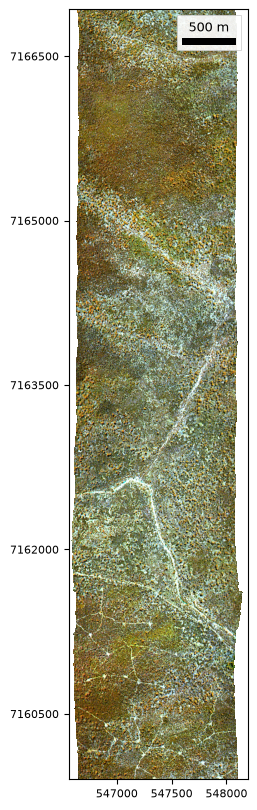

In [4]:
# Create the matplotlib figure
fig, ax = plt.subplots(figsize=(10, 10))

# Visualise with bands 32 (NIR), 19 (Red Edge) and 1 (Blue).
# The map functions return the matplotlib image (AxesImage) they draw.
im = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[32, 19, 1],
    img_stch=rsgispy.IMG_STRETCH_STDEV,
    show_scale_bar=True,
)

# 5. Adding Wavelengths to the image meta-data

It is often useful to have the wavelengths of the bands in the image metadata when processing hyperspectral data. To set the wavelengths we need to know what the wavelengths are. This is given in ‘hymap_wavelengths.json’ file which when read into Python will be represented as a dict data structure. 

Within the GDAL data model, image data allow metadata to be added to both the image and individual image bands. We will add the wavelength and the full width half maximum (FWHM) of that wavelength to each image band. Using the wavelength and the FWHM we can represent a simplified sensor response function as a gaussian.


In [5]:
hymap_metadata = rsgispy.tools.jsonio.read_json_to_dict(hymap_meta_file)

# Get the number of image bands in the input image.
n_bands = rsgispy.imageutils.metadata.get_img_band_count(input_img)

# Iterate the through the image bands to define the wavelength/fwhm
# Note, image band numbers start at 1 while array indexing starts at 0.
for n in tqdm.tqdm(range(n_bands)):
    rsgispy.imageutils.metadata.set_img_band_metadata(
        input_img, n + 1, "wavelength", "{}".format(hymap_metadata["wavelength"][n])
    )
    rsgispy.imageutils.metadata.set_img_band_metadata(
        input_img, n + 1, "wavelength_units", "Nanometers"
    )
    rsgispy.imageutils.metadata.set_img_band_metadata(
        input_img, n + 1, "fwhm", "{}".format(hymap_metadata["fwhm"][n])
    )

  0%|          | 0/126 [00:00<?, ?it/s]

You can view this metadata using the `gdalinfo` command line tool (`gdalinfo outputs/hymap_injune_subset.tif`) or, as below, from Python with `get_img_band_info`, which returns a pandas DataFrame with a row per band: the band name (description), data type, no data value, colour interpretation and a column for each band metadata item. Given there are 126 bands, only the first five are shown.

In [6]:
band_info = rsgispy.imageutils.metadata.get_img_band_info(input_img)
# There is a column for every band metadata item (including the statistics
# GDAL has written), so just show the band name, data type and spectral metadata.
info_cols = ["name", "datatype", "no_data", "wavelength", "wavelength_units", "fwhm"]
band_info[info_cols].head(5)

,name,datatype,no_data,wavelength,wavelength_units,fwhm
band,,,,,,
1,Band 1,int16,0.0,446.100006,Nanometers,15.0
2,Band 2,int16,0.0,456.700012,Nanometers,15.1
3,Band 3,int16,0.0,472.200012,Nanometers,17.0
4,Band 4,int16,0.0,487.5,Nanometers,16.0
5,Band 5,int16,0.0,502.200012,Nanometers,16.200001


# 6. Setting Image Band Names

Often, within the GIS software we are using to visualise the data the band are simply names based on their band number. You can also set the band name or description to a user defined piece of text. This can be useful when there are large number of bands and you want to know which one is which. 


In [7]:
# Iterate through bands to create band names which is the
# wavelength and unit (e.g., 000nm).
band_names = []
for n in range(n_bands):
    band_names.append("{}nm".format(int(hymap_metadata["wavelength"][n])))

# Write the band names to the image.
rsgispy.imageutils.metadata.set_band_names(input_img, band_names)

You can see the band names (the `name` column) using `gdalinfo` or `get_img_band_info`, as below; if you open the image in QGIS or TuiView you will also see that the band names have changed. In the GDAL data model the band name is the band "Description".

In [8]:
band_info = rsgispy.imageutils.metadata.get_img_band_info(input_img)
band_info[info_cols].head(5)

,name,datatype,no_data,wavelength,wavelength_units,fwhm
band,,,,,,
1,446nm,int16,0.0,446.100006,Nanometers,15.0
2,456nm,int16,0.0,456.700012,Nanometers,15.1
3,472nm,int16,0.0,472.200012,Nanometers,17.0
4,487nm,int16,0.0,487.5,Nanometers,16.0
5,502nm,int16,0.0,502.200012,Nanometers,16.200001


# 7. Manual Band Subset

It can often be useful to subset the bands to just those we want to use for visualisation. This can make the visualisation faster and easier with smaller file sizes. 

You can use the code below to subset the data to the bands we are using for visualisation: NIR (band 42; 1050nm), Red-Edge (band 19; 716nm) and Blue (band 1; 446nm)

The output is a GeoTIFF, which can be opened in QGIS and other software. rsgispy writes GeoTIFFs with DEFLATE compression (and tiling) by default, so no extra settings are needed.

**RSGISLib users:** the `set_env_vars_lzw_gtiff_outs()` call is no longer needed, and `select_img_bands` takes the band list before the (keyword-only) format and data type.

In [9]:
# Define the output image
output_img = os.path.join(out_dir, "hymap_injune_subset_b42b19b1.tif")

# bands to be selected and the order they will be outputted
bands = [42, 19, 1]
rsgispy.imageutils.bands.select_img_bands(
    input_img,
    output_img,
    bands,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_16INT,
    no_data_val=0,
    calc_stats=False,
)

# Calculate image pyramids and statistics
rsgispy.imageutils.stats.pop_img_stats(output_img, no_data_val=0, calc_pyramids=True)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

# 8. Create Valid Mask

The valid mask has a value of 1 where the image has data (i.e., not 0 in every band) and 0 elsewhere. It is a thematic image, so `set_thematic_classes` marks it as thematic, gives the class a name and a colour, and calculates its statistics and pyramids.

**RSGISLib users:** rsgispy does not use raster attribute tables (RATs), so `rastergis.pop_rat_img_stats` and `rastergis.set_class_names_colours` are replaced by `rsgispy.imageutils.colourtable.set_thematic_classes`, which stores the class names in the image (they are used for map legends).

In [10]:
vld_msk_img = os.path.join(out_dir, "hymap_injune_subset_vld_msk.tif")

rsgispy.imageutils.masking.gen_valid_mask(
    input_img, vld_msk_img, gdalformat="GTIFF", no_data_val=0.0, calc_stats=False
)

# It is a thematic image: define it as such, with a class name and colour,
# and populate the statistics and pyramids.
rsgispy.imageutils.colourtable.set_thematic_classes(vld_msk_img, {1: ("Valid", "#2C7BB6")})

  0%|          | 0/33 [00:00<?, ?it/s]

## Visualise the Valid Mask

`create_map_panels` draws maps side by side with the same extent, one scale bar and north arrow, and a shared legend for the thematic panels (here using the class name stored by `set_thematic_classes`).

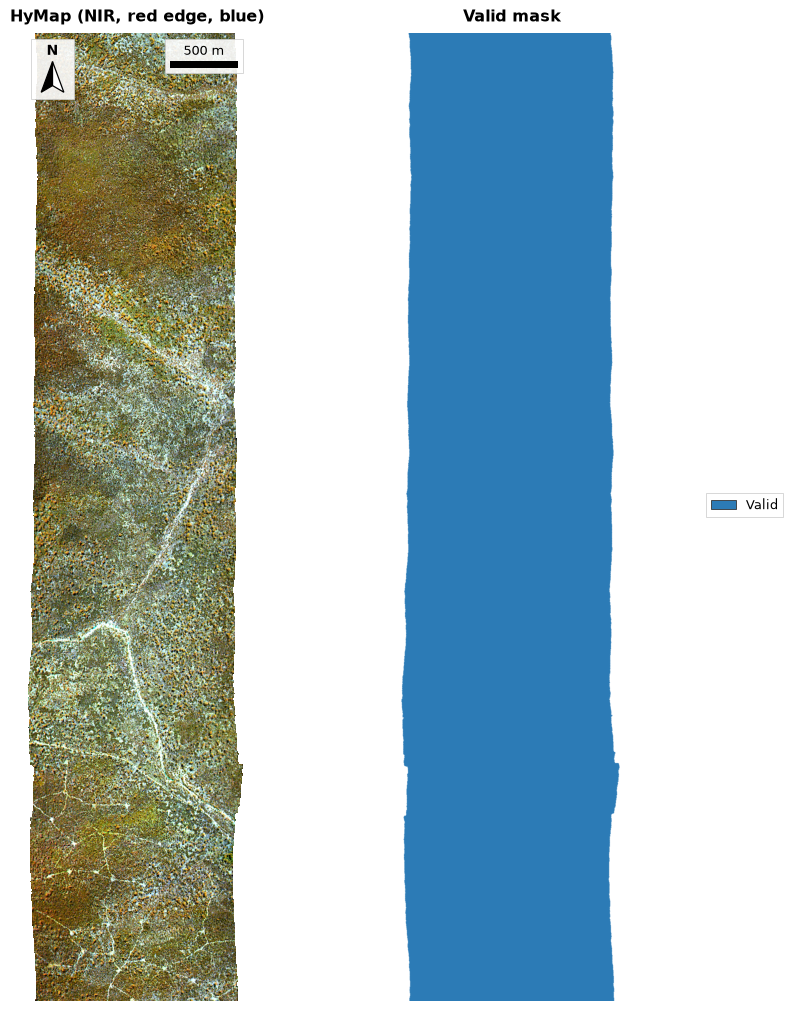

In [11]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="HyMap (NIR, red edge, blue)",
        ),
        map_layout.MapPanel("thematic", vld_msk_img, title="Valid mask"),
    ],
    figsize=(7.5, 10),
)

# 9. Spectral Smoothing

A common analysis which is applied to hyperspectral data is spectral smoothing. A common approach is Savitzky-Golay filtering which locally fits a polynomial within a sliding window along the spectra. Parameters for Savitzky-Golay filter are therefore the size of the window and the order of the polynomial function. Increasing the window size will produce a smoother output but will also remove more features from the spectra.

In [12]:
spec_smooth_img = os.path.join(out_dir, "hymap_injune_subset_smoothed.tif")

rsgispy.imagespectral.preprocessing.spectral_smoothing(
    input_img,
    spec_smooth_img,
    valid_msk_img=vld_msk_img,
    valid_msk_val=1,
    win_len=5,
    polyorder=3,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_16INT,
    calc_stats=True,
)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

# 9.1 Visualise Spectra

You might want to have a play with the different parameters for the smoothing and visualise the outputs. Try changing the order of the polynomial (polyorder) and the window length (i.e., number of values for the local fit) (win_len). 

In [13]:
# Get image pixel values for pixel 50, 100
orig_pxl_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    input_img, x_pxl_coord=50, y_pxl_coord=100
)
smth_pxl_vals = rsgispy.imageutils.arrays.get_img_pxl_column(
    spec_smooth_img, x_pxl_coord=50, y_pxl_coord=100
)

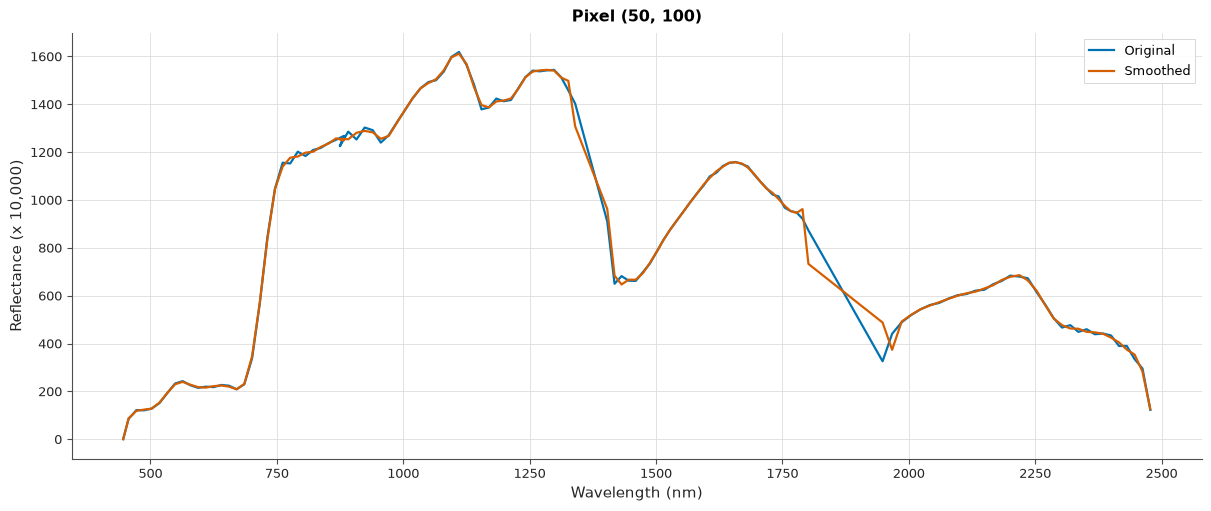

In [14]:
# Plot the original and smoothed spectra of the pixel
fig, ax = spectra.plot_spectra(
    {"Original": orig_pxl_vals, "Smoothed": smth_pxl_vals},
    wavelengths=hymap_metadata["wavelength"],
    y_label="Reflectance (x 10,000)",
    title="Pixel (50, 100)",
    figsize=(12, 5),
)

# 9.2 Continuum Removal of the Image Spectra

In notebook 1, continuum removal was applied to single spectra with `calc_continuum_removal`. `calc_continuum_removal_img` applies it to the spectrum of every pixel of an image: the output has one band for each input band within the wavelength range (named by its wavelength), with values from 0 to 1, where 1 is on the continuum and lower values are deeper absorption.

Below it is applied to the chlorophyll absorption region (530-750 nm) of the smoothed image. The continuum removal functions need wavelengths that increase from band to band, which is not quite the case for HyMap: its VNIR and SWIR detectors overlap, so band 30 (882.5 nm) comes before band 31 (874.6 nm). Therefore, the bands within the wavelength range are selected first. The continuum removal of the pixel plotted above:

Bands 7 to 21


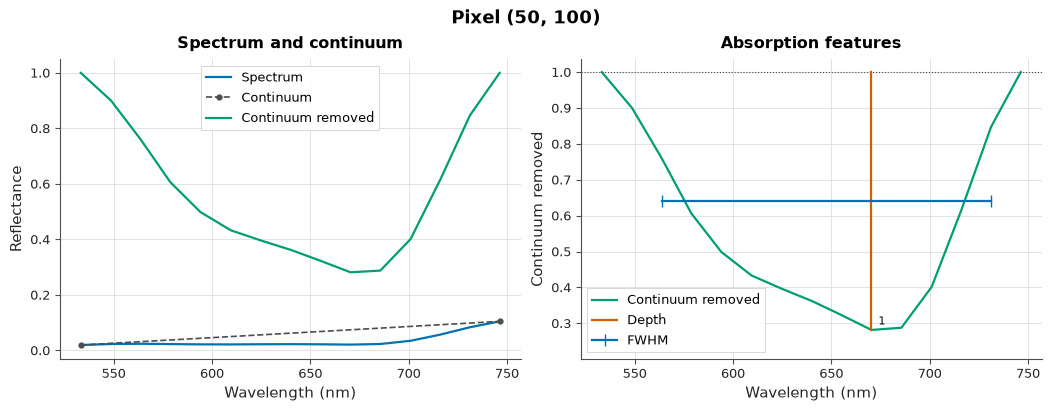

In [15]:
# The bands (and their wavelengths) within the 530-750 nm range.
cr_bands = [
    n + 1 for n, wvl in enumerate(hymap_metadata["wavelength"]) if 530 <= wvl <= 750
]
cr_wvls = [hymap_metadata["wavelength"][band - 1] for band in cr_bands]
print("Bands {} to {}".format(cr_bands[0], cr_bands[-1]))

# The values are divided by 10,000 to give reflectance (0-1), the same
# scale as the continuum removed spectrum.
cr_pxl = spectra.calc_continuum_removal(
    smth_pxl_vals[numpy.array(cr_bands) - 1] / 10000, cr_wvls
)
fig, axs = spectra.plot_continuum_removal(cr_pxl, title="Pixel (50, 100)")

In [16]:
# Select the bands in the 530-750 nm range from the smoothed image
spec_smooth_sub_img = os.path.join(out_dir, "hymap_injune_subset_smoothed_530_750.tif")
rsgispy.imageutils.bands.select_img_bands(
    spec_smooth_img,
    spec_smooth_sub_img,
    cr_bands,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_16INT,
    no_data_val=0,
    calc_stats=False,
)

# Continuum removal of every pixel (no data = 0 in the input, -9999 in the output)
cr_img = os.path.join(out_dir, "hymap_injune_subset_smoothed_cr.tif")
spectra.calc_continuum_removal_img(
    spec_smooth_sub_img, cr_img, wavelengths=cr_wvls, no_data_val=0
)

# The output bands are named by their wavelength: find the band closest to
# the red chlorophyll absorption (680 nm).
cr_band_info = rsgispy.imageutils.metadata.get_img_band_info(cr_img)
cr_band_wvls = cr_band_info["name"].astype(float)
cr_band = int((cr_band_wvls - 680).abs().idxmin())
print("{} bands; band {} is {} nm".format(len(cr_band_info), cr_band, cr_band_wvls[cr_band]))

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

15 bands; band 11 is 685.6 nm


The continuum removed value at the absorption maximum is low (a deep feature) where the canopy absorbs strongly, i.e. where there is dense, green vegetation, and close to 1 where there is little absorption (e.g., bare ground):

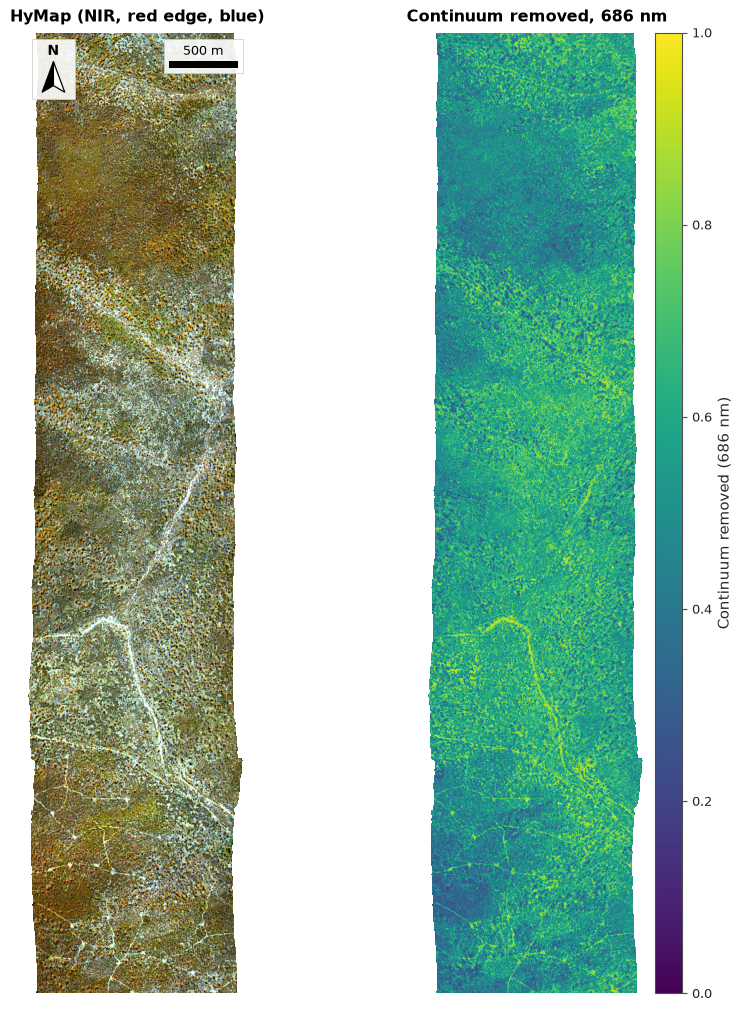

In [17]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="HyMap (NIR, red edge, blue)",
        ),
        map_layout.MapPanel(
            "cmap", cr_img, bands=cr_band, cmap_name="viridis", vmin=0, vmax=1,
            show_colour_bar=True,
            cbar_label="Continuum removed ({:.0f} nm)".format(cr_band_wvls[cr_band]),
            title="Continuum removed, {:.0f} nm".format(cr_band_wvls[cr_band]),
        ),
    ],
    figsize=(8, 10),
)

# 10. Dimensionality Reduction

With so many image bands which are close in wavelength and therefore highly correlated to one another it is often desirable to perform a dimensionality reduction, such as principal component analysis to reduce the number of bands to make visualisation easier and in some cases simplifying and speeding up further data analysis (e.g., image segmentation, classification)

# 10.1 Principal Component Analysis (PCA)

PCA is the most common dimensionality reduction method so let’s try that first. `calc_pca` reads the image in blocks, so it uses every valid pixel (rather than a sample) to calculate the band covariance matrix, and returns a dictionary with the eigenvalues and the proportion of the variance described by each component. Writing all 126 components would create a very large image, so we first output just the first 10 components to look at the variance they describe.

**RSGISLib users:** `perform_image_pca` is replaced by `rsgispy.imagespectral.transforms.calc_pca`; there is no pixel sampling (`pxl_n_sample`) and no separate eigenvector file (use `out_stats_json` to save the eigenvalues and loadings).

In [18]:
pca_img = os.path.join(out_dir, "hymap_injune_subset_pca10.tif")

pca_info = rsgispy.imagespectral.transforms.calc_pca(
    input_img,
    pca_img,
    n_components=10,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=0,
    calc_stats=False,
)

pca_var = pandas.DataFrame(
    {
        "explained variance (%)": numpy.array(pca_info["explained_variance_ratio"]) * 100,
        "cumulative variance (%)": numpy.array(pca_info["cumulative_variance_ratio"]) * 100,
    },
    index=pandas.Index(["PC{}".format(i + 1) for i in range(10)], name="component"),
)
pca_var.round(2)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

,explained variance (%),cumulative variance (%)
component,,
PC1,86.78,86.78
PC2,11.32,98.10
PC3,0.81,98.90
PC4,0.54,99.44
PC5,0.28,99.73
PC6,0.07,99.80
PC7,0.06,99.85
PC8,0.03,99.88
PC9,0.02,99.90


In the table you will see the amount of variance described by each principal component: about 87% is described by the first PC, 11% by the second PC and 0.8% by the third PC, while the first five components together describe more than 99.7% of the variance. *Note, your values might differ slightly.*

We could therefore output a PCA image with just the first 5 principal components:


In [19]:
pca_img = os.path.join(out_dir, "hymap_injune_subset_pca.tif")
out_pca_stats_file = os.path.join(out_dir, "hymap_injune_subset_pca_stats.json")

pca_info = rsgispy.imagespectral.transforms.calc_pca(
    input_img,
    pca_img,
    n_components=5,
    out_stats_json=out_pca_stats_file,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=0,
    calc_stats=True,
)
os.remove(os.path.join(out_dir, "hymap_injune_subset_pca10.tif"))

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

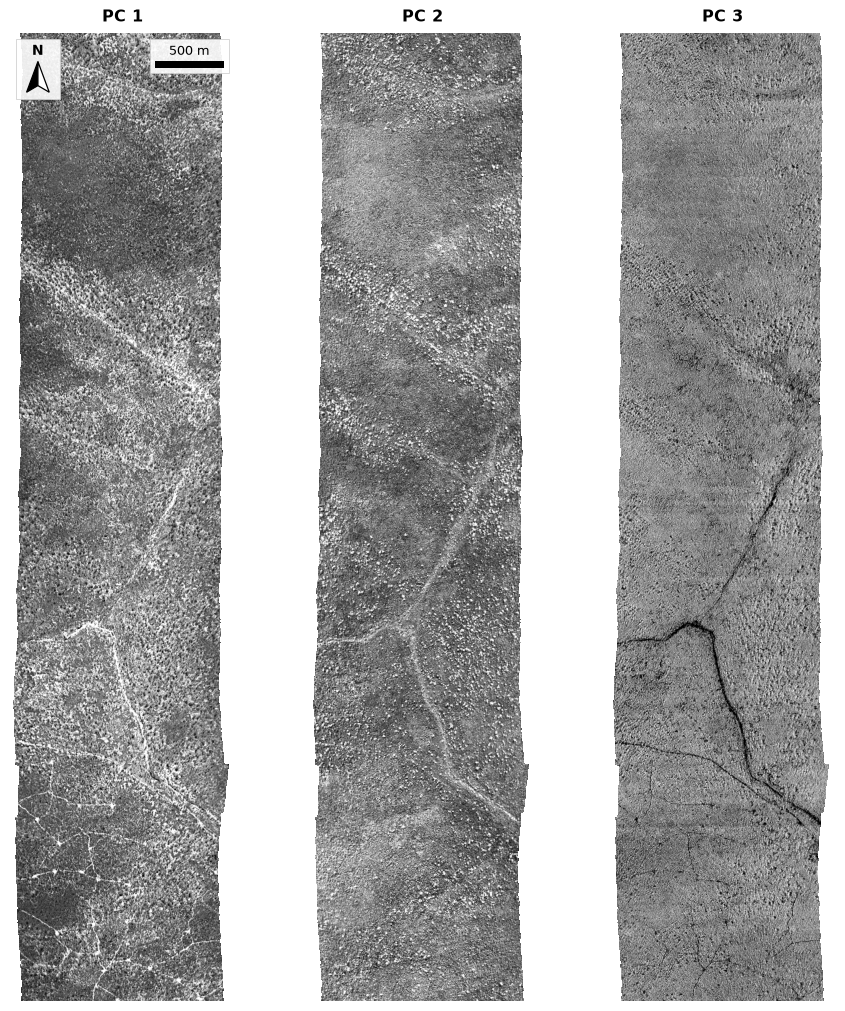

In [20]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", pca_img, bands=[1], img_stch=rsgispy.IMG_STRETCH_STDEV, title="PC 1"
        ),
        map_layout.MapPanel(
            "rgb", pca_img, bands=[2], img_stch=rsgispy.IMG_STRETCH_STDEV, title="PC 2"
        ),
        map_layout.MapPanel(
            "rgb", pca_img, bands=[3], img_stch=rsgispy.IMG_STRETCH_STDEV, title="PC 3"
        ),
    ],
    figsize=(9, 10),
)

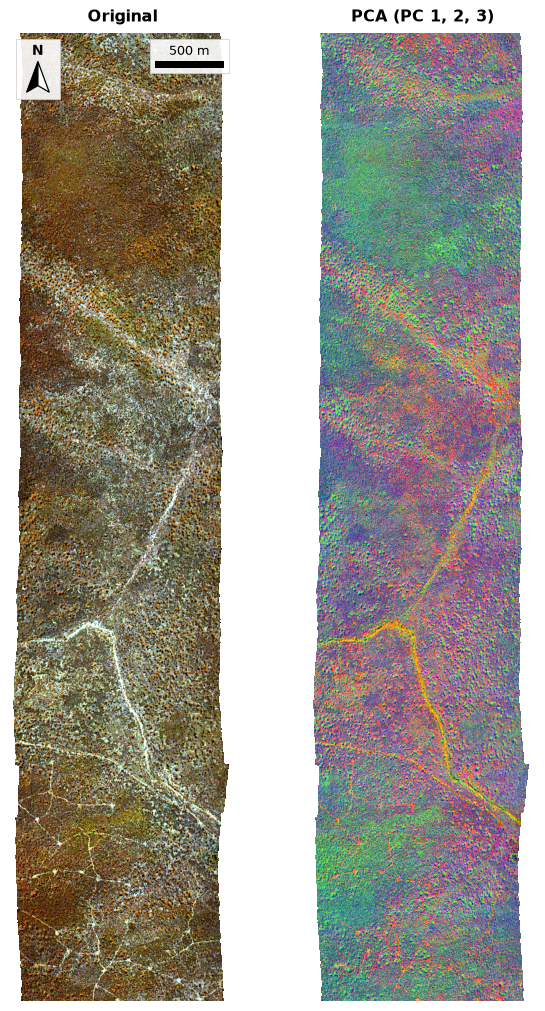

In [21]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", pca_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="PCA (PC 1, 2, 3)",
        ),
    ],
    figsize=(6, 10),
)

# 10.2 Minimum Noise Fraction (MNF)

The MNF transformation is based on PCA but first uses the noise covariance matrix to decorrelate and rescale the noise in the data (noise whitening) before applying the PCA. This has been demonstrated to produce better results with less noise than PCA.

**RSGISLib users:** `perform_image_mnf` is replaced by `rsgispy.imagespectral.transforms.calc_mnf`, which estimates the noise from the differences between neighbouring pixels using every valid pixel and needs no temporary directory.

In [22]:
mnf_img = os.path.join(out_dir, "hymap_injune_subset_mnf.tif")

# As we know from the PCA we only need 5 components.
mnf_info = rsgispy.imagespectral.transforms.calc_mnf(
    input_img,
    mnf_img,
    n_components=5,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=0,
    calc_stats=True,
)

pandas.DataFrame(
    {"MNF eigenvalue": mnf_info["mnf_eigenvalues"], "estimated SNR": mnf_info["snr_estimates"]},
    index=pandas.Index(["MNF{}".format(i + 1) for i in range(5)], name="component"),
).round(1)

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

  0%|          | 0/33 [00:00<?, ?it/s]

,MNF eigenvalue,estimated SNR
component,,
MNF1,9.6,8.6
MNF2,7.9,6.9
MNF3,6.3,5.3
MNF4,5.2,4.2
MNF5,4.8,3.8


The MNF components are ordered by their signal-to-noise ratio (SNR): the eigenvalue of each component is the ratio of the signal variance to the noise variance (so SNR = eigenvalue - 1), and the first component has by far the highest SNR. Components with an eigenvalue close to 1 are dominated by noise.

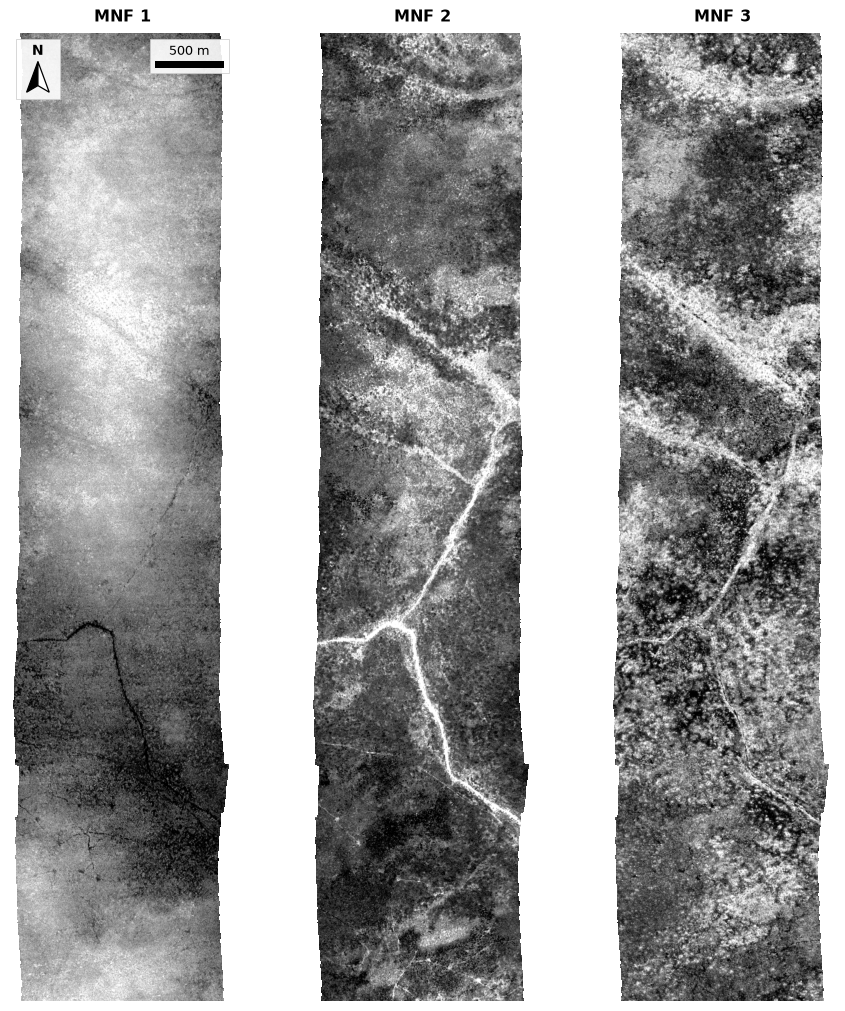

In [23]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", mnf_img, bands=[1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE, title="MNF 1"
        ),
        map_layout.MapPanel(
            "rgb", mnf_img, bands=[2], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE, title="MNF 2"
        ),
        map_layout.MapPanel(
            "rgb", mnf_img, bands=[3], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE, title="MNF 3"
        ),
    ],
    figsize=(9, 10),
)

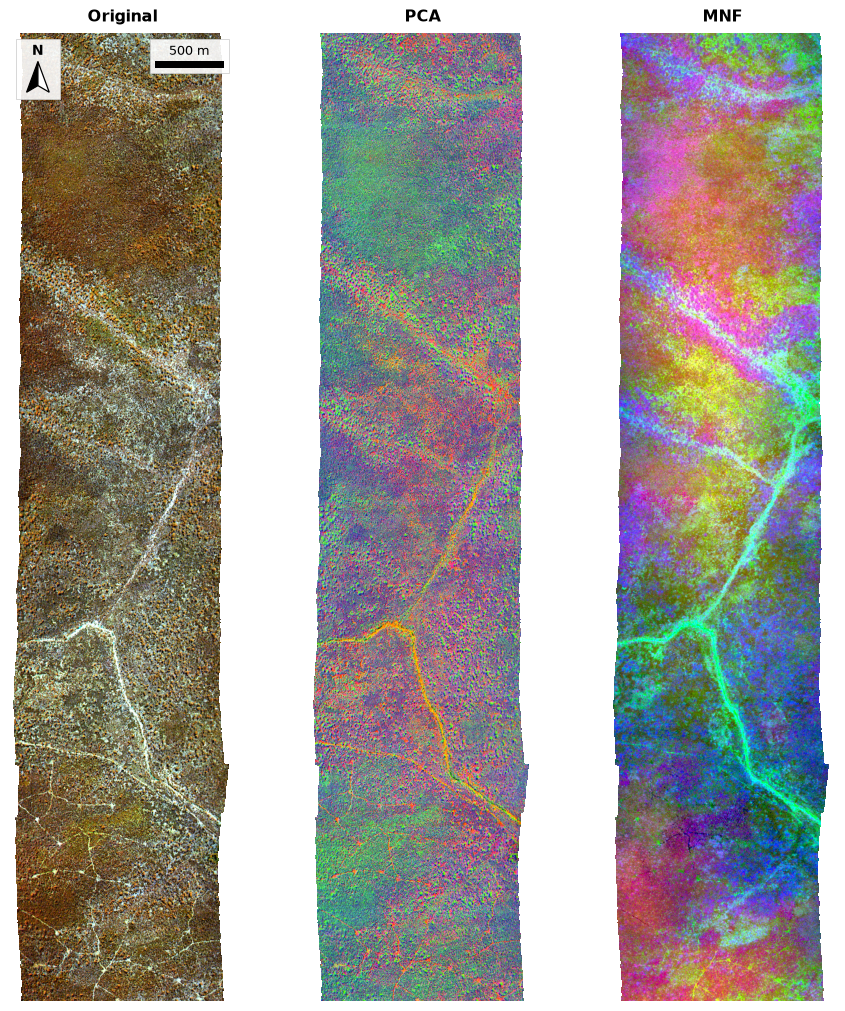

In [24]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[32, 19, 1], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
            title="Original",
        ),
        map_layout.MapPanel(
            "rgb", pca_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV, title="PCA"
        ),
        map_layout.MapPanel(
            "rgb", mnf_img, bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_STDEV, title="MNF"
        ),
    ],
    figsize=(9, 10),
)